# Customer Churn Prediction: Telco

**Business question:** which customers are about to cancel, and what can the retention team do about it?

This notebook rebuilds my Digital Skola *Conqueror Project 1* end to end: data cleaning, exploratory analysis,
churn drivers, a model comparison with and without imbalance handling, and a ranked list the retention team can act on.

**Data:** IBM Telco Customer Churn sample, 7,043 customers, 21 columns (`data/telco_customer_churn.csv`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             confusion_matrix, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
df = pd.read_csv("data/telco_customer_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges is stored as text; 11 brand-new customers (tenure = 0) have a blank value.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum(),
      "| their tenure:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # no bill yet, so 0 is the true value
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
print("Duplicates:", df.duplicated().sum())
print("Churn rate:", round(df["churn_flag"].mean(), 3))

Blank TotalCharges: 11 | their tenure: [0]
Duplicates: 0
Churn rate: 0.265


## 2. What drives churn?

About **1 in 4 customers churned (26.5%)**, so the classes are imbalanced. The charts below compare churn
rates across the variables the business can act on.

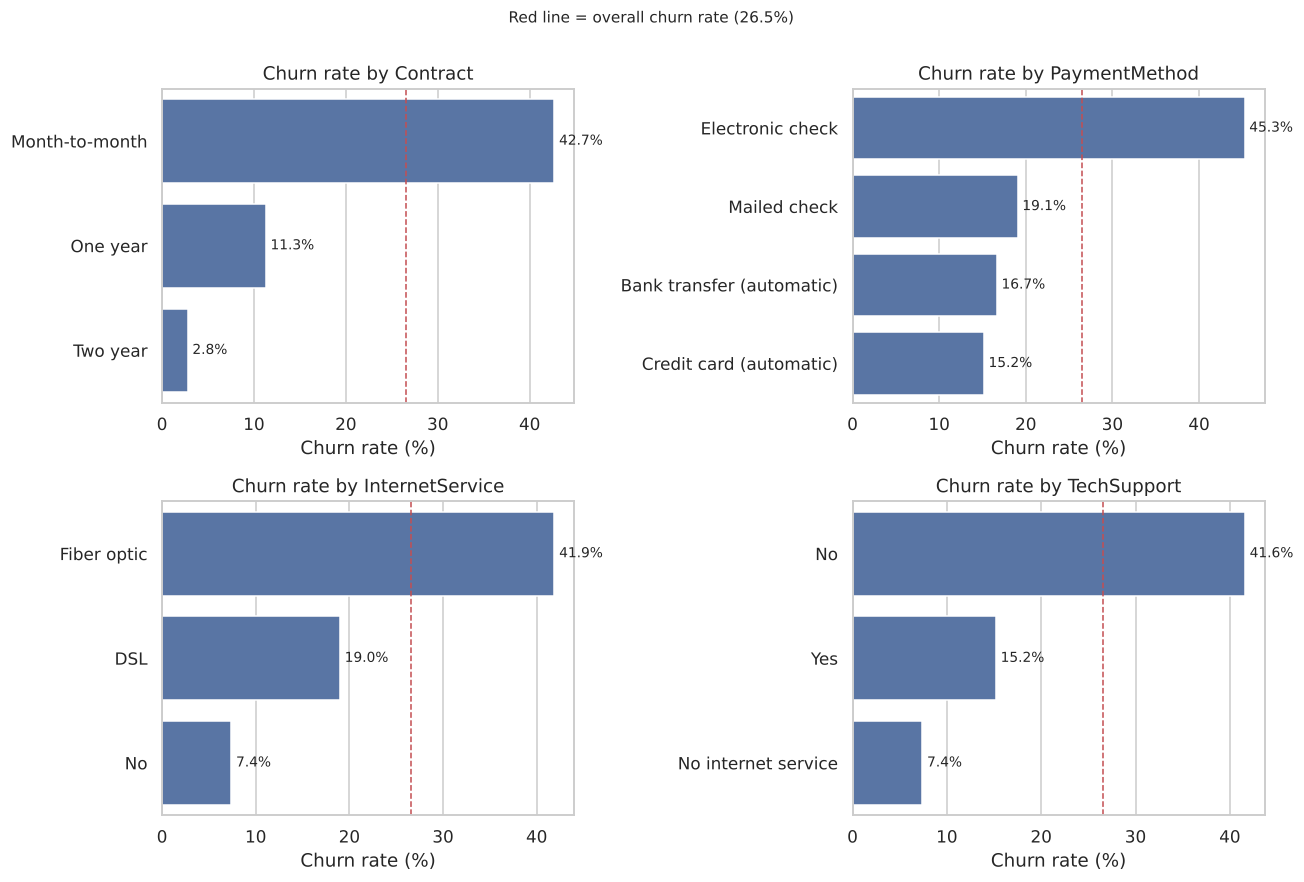

In [4]:
def churn_rate(col):
    return (df.groupby(col, observed=True)["churn_flag"].mean()
              .sort_values(ascending=False).mul(100).round(1))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Contract", "PaymentMethod", "InternetService", "TechSupport"]):
    rate = churn_rate(col)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#4C72B0")
    ax.axvline(df["churn_flag"].mean() * 100, color="#C44E52", ls="--", lw=1)
    ax.set(title=f"Churn rate by {col}", xlabel="Churn rate (%)", ylabel="")
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=9)
plt.suptitle("Red line = overall churn rate (26.5%)", y=1.0, fontsize=10)
plt.tight_layout()

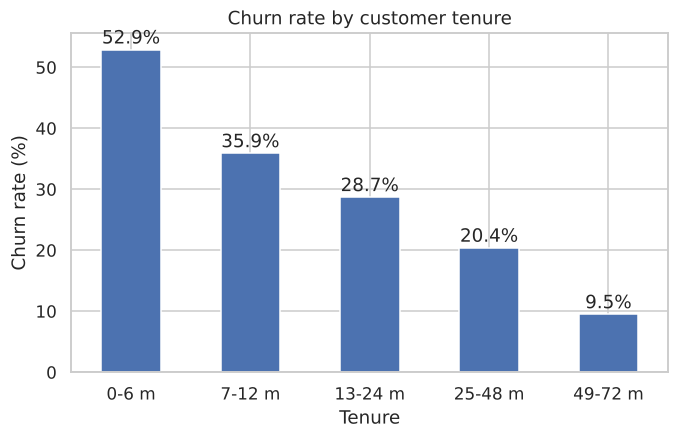

,churn_flag
tenure_band,
0-6 m,52.9
7-12 m,35.9
13-24 m,28.7
25-48 m,20.4
49-72 m,9.5


In [5]:
df["tenure_band"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                           labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])
rate = churn_rate("tenure_band").reindex(["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])
ax = rate.plot(kind="bar", color="#4C72B0", figsize=(7, 4), rot=0)
ax.set(title="Churn rate by customer tenure", ylabel="Churn rate (%)", xlabel="Tenure")
for i, v in enumerate(rate.values):
    ax.text(i, v + 1, f"{v}%", ha="center")
rate

**Key findings**

1. **Contract is the strongest signal.** Month-to-month customers churn at 42.7%, versus 11.3% on one-year and 2.8% on two-year contracts.
2. **The first six months are critical.** 52.9% of customers in their first six months leave; after four years it drops to 9.5%.
3. **Electronic check payers churn at 45.3%**, about three times the rate of automatic bank or card payments (15–17%).
4. **Fiber optic customers churn at 41.9%** and customers **without tech support at 41.6%**, which points to a service-quality or price-value issue.

## 3. Prepare features

In [6]:
target = "churn_flag"
drop_cols = ["customerID", "Churn", "churn_flag", "tenure_band"]
X = df.drop(columns=drop_cols)
y = df[target]
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])
print("Train:", X_train.shape, "| Test:", X_test.shape,
      "| churn share train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19) | churn share train/test: 0.265 0.265


## 4. Compare models, with and without imbalance handling

Accuracy is misleading here: predicting "no churn" for everyone is already 73% accurate. The business cares about
**recall** (how many real churners we catch) while keeping **precision** reasonable (how many flagged customers are real churners).
Imbalance is handled with **class weighting**, which makes each churner count more during training. This is an
alternative to SMOTE oversampling that adds no synthetic rows.

All scores are 5-fold stratified cross-validation on the training set.

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                       class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "recall", "precision", "f1", "accuracy"])
    rows.append({"model": name, **{k.replace("test_", ""): v.mean() for k, v in s.items() if k.startswith("test_")}})
cv_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
cv_results

,roc_auc,recall,precision,f1,accuracy
model,,,,,
Gradient Boosting,0.848,0.529,0.662,0.588,0.803
Logistic Regression,0.846,0.544,0.653,0.593,0.802
Logistic Regression (balanced),0.846,0.801,0.517,0.628,0.749
Random Forest,0.844,0.504,0.668,0.574,0.801
Random Forest (balanced),0.844,0.764,0.536,0.630,0.762


Class weighting raises recall from roughly half of churners to about **8 in 10**, at the cost of lower precision.
ROC-AUC barely changes, so the ranking quality stays the same. Only the decision threshold shifts.
For a retention campaign, missing a churner usually costs more than an extra discount, so the **balanced logistic regression**
is chosen: its ROC-AUC is within 0.002 of the best model, it catches the most churners, and its coefficients are easy to explain to the business.

## 5. Final model on the held-out test set

ROC-AUC      0.842
Recall       0.783
Precision    0.505
F1           0.614


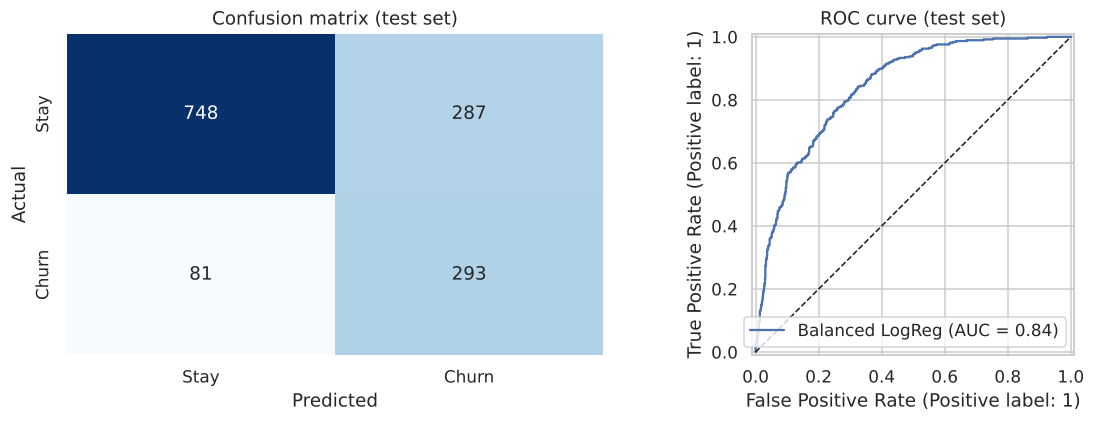

In [8]:
final = Pipeline([("prep", preprocess),
                  ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
final.fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
test_scores = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, proba),
    "Recall": recall_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "F1": f1_score(y_test, pred),
}).round(3)
print(test_scores.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[0].set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name="Balanced LogReg")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()

## 6. How useful is the ranking for the retention team?

If the team can only call a limited number of customers, the question is how many churners the top of the list contains.

Calling the riskiest 20% of customers reaches 50% of all churners
Calling the riskiest 40% of customers reaches 78% of all churners


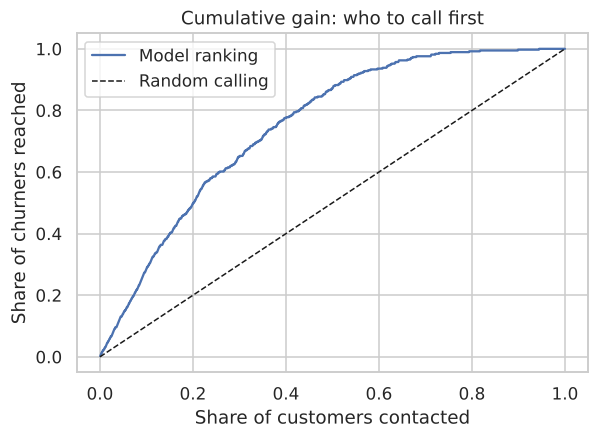

In [9]:
ranked = pd.DataFrame({"proba": proba, "churn": y_test.values}).sort_values("proba", ascending=False)
ranked["share_contacted"] = np.arange(1, len(ranked) + 1) / len(ranked)
ranked["churners_caught"] = ranked["churn"].cumsum() / ranked["churn"].sum()
gain = ranked.set_index("share_contacted")["churners_caught"]

top20 = gain[gain.index <= 0.20].iloc[-1]
top40 = gain[gain.index <= 0.40].iloc[-1]
print(f"Calling the riskiest 20% of customers reaches {top20:.0%} of all churners")
print(f"Calling the riskiest 40% of customers reaches {top40:.0%} of all churners")

ax = gain.plot(figsize=(6, 4), label="Model ranking")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random calling")
ax.set(xlabel="Share of customers contacted", ylabel="Share of churners reached",
       title="Cumulative gain: who to call first")
ax.legend();

## 7. Which factors push churn up or down?

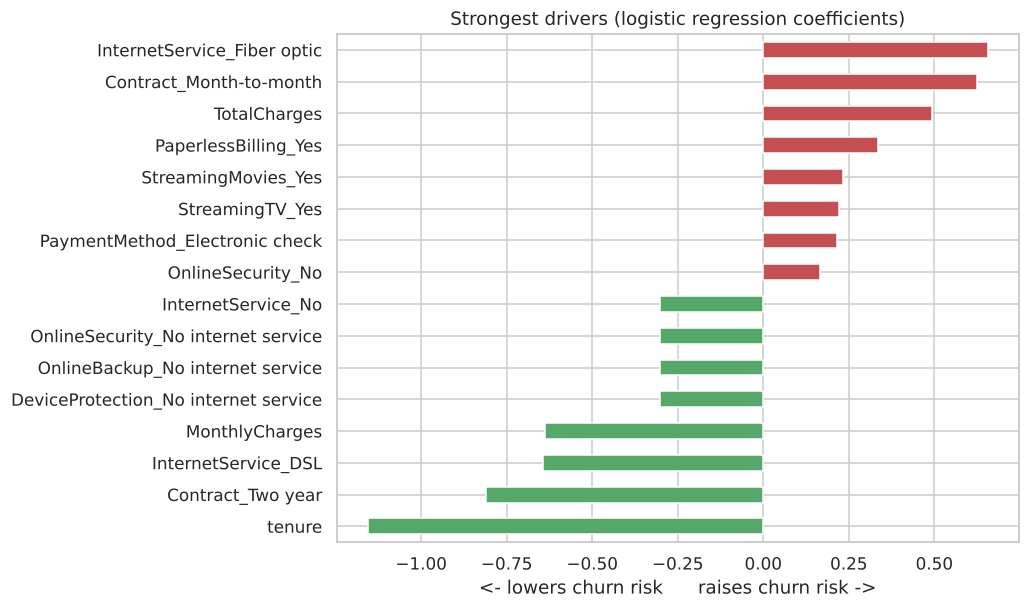

,0
tenure,-1.16
Contract_Two year,-0.81
InternetService_DSL,-0.64
MonthlyCharges,-0.64
DeviceProtection_No internet service,-0.30
OnlineBackup_No internet service,-0.30
OnlineSecurity_No internet service,-0.30
InternetService_No,-0.30
OnlineSecurity_No,0.17
PaymentMethod_Electronic check,0.22


In [10]:
names = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["model"].coef_[0], index=names)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()
ax = top.plot(kind="barh", figsize=(8, 6),
              color=["#55A868" if v < 0 else "#C44E52" for v in top.values])
ax.set(title="Strongest drivers (logistic regression coefficients)",
       xlabel="<- lowers churn risk      raises churn risk ->")
top.round(2)

In [11]:
summary_text = (f"Test ROC-AUC {test_scores['ROC-AUC']}, recall {test_scores['Recall']}, "
                f"precision {test_scores['Precision']}; top 20% of the ranking reaches {top20:.0%} of churners.")
print(summary_text)

Test ROC-AUC 0.842, recall 0.783, precision 0.505; top 20% of the ranking reaches 50% of churners.


## 8. Recommendations for the business

1. **Move month-to-month customers onto longer contracts.** Offer a discount or bonus for switching to a 1-year plan, targeted at the model's highest-risk customers.
2. **Run a 90-day onboarding programme.** More than half of churn happens in the first six months, so add a welcome call, a usage check-in and a quick fix for early issues.
3. **Nudge electronic-check payers to autopay.** A small incentive to switch to automatic card or bank payment targets the group that churns at 45%.
4. **Bundle tech support and online security for fiber customers.** These services are linked with much lower churn and address the fiber group's high risk.
5. **Call from the top of the list.** Score customers monthly and contact them in order of risk. The cumulative-gain curve shows how much a limited call budget can cover.

*Limitations:* this is a public sample dataset. Before rolling it out, validate on recent company data and measure the effect with an A/B test.